In [1]:
%pip install scikit-learn statsmodels seaborn scipy

Defaulting to user installation because normal site-packages is not writeable
  Using cached statsmodels-0.15.0-cp314-cp314-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
Using cached statsmodels-0.15.0-cp314-cp314-win_amd64.whl (11.3 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)

   ---------------------------------------- 0/4 [patsy]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   ------------------------------ --------- 3/4 [statsmodels]
   ------------------------------ --------- 3/4 [statsmodels]
   ------------------------------ --------- 3/4 [statsmodels]
   ------------------------------ -------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

NameError: name 'pd' is not defined

In [11]:
print("Missing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [13]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Sex"], df["Survived"])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", round(chi2, 3))
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Gender and survival are significantly associated.")
else:
    print("Fail to reject H0: Evidence of association is insufficient.")

Chi-square statistic: 260.717
P-value: 1.1973570627755645e-58
Reject H0: Gender and survival are significantly associated.


In [15]:
# Select relevant columns
model_df = df[
    ["Survived", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]
].copy()

# Fill missing values
model_df["Age"] = model_df["Age"].fillna(model_df["Age"].median())

# Convert gender into numeric values
model_df["Sex"] = model_df["Sex"].map({"male": 0, "female": 1})

# Check for missing values
print("Missing values after cleaning:")
print(model_df.isnull().sum())

print("\nPrepared dataset shape:", model_df.shape)
model_df.head()

Missing values after cleaning:
Survived    0
Pclass      0
Sex         0
Age         0
Fare        0
SibSp       0
Parch       0
dtype: int64

Prepared dataset shape: (891, 7)


,Survived,Pclass,Sex,Age,Fare,SibSp,Parch
0,0,3,0,22.0,7.2500,1,0
1,1,1,1,38.0,71.2833,1,0
2,1,3,1,26.0,7.9250,0,0
3,1,1,1,35.0,53.1000,1,0
4,0,3,0,35.0,8.0500,0,0


In [16]:
X = model_df[["Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]]
y = model_df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.804
ROC-AUC: 0.852

Confusion Matrix:
[[95 15]
 [20 49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [17]:
# Logistic regression coefficients
logistic_model = model.named_steps["logistic"]

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

print("Logistic Regression Coefficients:")
print(coef_table.sort_values(
    by="Coefficient", ascending=False
).round(4))

Logistic Regression Coefficients:
  Feature  Coefficient
1     Sex       1.2969
3    Fare       0.1464
5   Parch      -0.0936
4   SibSp      -0.2868
2     Age      -0.5014
0  Pclass      -0.8936


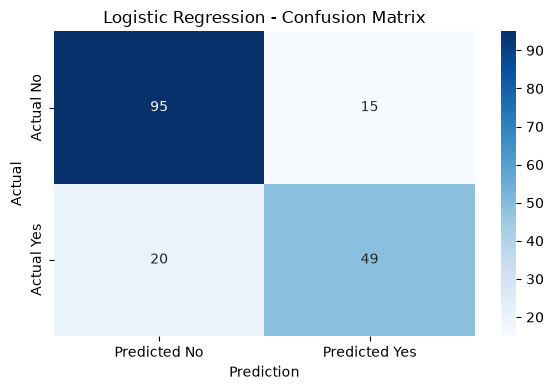

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(y_prob, y_test - y_prob, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Probability of Survival")
plt.ylabel("Actual Outcome - Predicted Probability")
plt.title("Logistic Regression Residual Diagnostic")
plt.tight_layout()
plt.show()

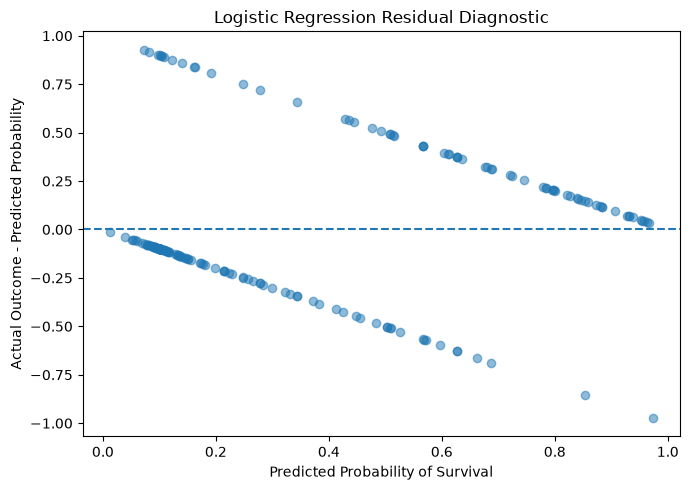

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(y_prob, y_test - y_prob, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Probability of Survival")
plt.ylabel("Actual Outcome - Predicted Probability")
plt.title("Logistic Regression Residual Diagnostic")
plt.tight_layout()
plt.show()

# Week 3: Statistical Modeling and Hypothesis Testing

## 1. Research Question
Are passenger characteristics such as gender, age, passenger class, fare, and family size associated with survival on the Titanic?

## 2. Hypothesis Testing
A Chi-square test was conducted to examine the relationship between gender and survival.

- **Chi-square statistic:** 260.717
- **P-value:** 1.197 × 10⁻⁵⁸
- **Significance level:** 0.05

Since the p-value is less than 0.05, the null hypothesis was rejected. The results indicate a statistically significant association between gender and survival.

## 3. Logistic Regression Results
A Logistic Regression model was trained using passenger class, gender, age, fare, siblings/spouses, and parents/children aboard.

- **Accuracy:** 80.4%
- **ROC-AUC:** 0.852
- **Test samples:** 179

The accuracy indicates that the model correctly classified approximately 80.4% of passengers in the test set. The ROC-AUC score of 0.852 indicates good ability to distinguish between passengers who survived and those who did not.

## 4. Confusion Matrix Interpretation

| | Predicted Not Survived | Predicted Survived |
|---|---:|---:|
| Actually Not Survived | 95 | 15 |
| Actually Survived | 20 | 49 |

The model correctly identified 95 passengers who did not survive and 49 passengers who survived. It incorrectly classified 15 non-survivors as survivors and 20 survivors as non-survivors.

## 5. Classification Report
- **Class 0 (Not Survived):** Precision = 0.83, Recall = 0.86, F1-score = 0.84.
- **Class 1 (Survived):** Precision = 0.77, Recall = 0.71, F1-score = 0.74.

The model performed somewhat better at identifying passengers who did not survive than at identifying passengers who survived.

## 6. Limitations
The dataset contains missing values, and the model uses only a subset of available passenger characteristics. Other relevant factors may not be included. Statistical association does not prove causation, and the results should not automatically be generalized to other populations.

## 7. Conclusion
The Chi-square test found a statistically significant association between gender and survival. Logistic Regression achieved 80.4% accuracy and a ROC-AUC of 0.852 on the held-out test set. These results suggest that the selected passenger characteristics provide useful information for predicting Titanic survival.